**ESTUDIO DE LOS DATOS Y LAS VARIABLES**
-

A lo largo de este archivo ipynb se lee el dataset con el que se va a trabajar en este proyecto. Se cargan los datos y se estudian sus características. El estudio consiste en una interpretación de sus valores y del enunciado para su futuro uso. Los resultados de esta primera parte se almacenan en una tabla que describe cada variable. 

A continuación, con las variables ya clasificadas y la tabla descriptiva construida se procede a estudiar el propio dataset y sus propiedades. Dicho estudio consiste en investigar el tipo de variables, su estructura general, valores nulos y valores duplicados entre otras caraceterísticas. De esta manera conoceré mejor el dataset con el que trabajaré posteriormente.

**1. Carga de datos**

Cargo los datos que usaré para construir mi modelo usando la librería pandas. Establezco correctamente la ruta dónde se encuentra el archivo a leer de manera que sea reproducible para futuros usuarios.

Una vez leo los datos estudio su formato y sus características.

In [ ]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
from unsupervised import obtener_vars_no_supervisado

df = pd.read_csv("../rendimiento_estudiantes.csv", sep=";")
df.head()

,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,otro_11o_ano,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,soltero/a,estudiante_internacional_licenciatura,1,turismo,diurna,educacion_secundaria,160.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_superior_grado,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,soltero/a,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,soltero/a,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_2o_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,casado/a,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado


Observamos las primeras 5 filas del dataset con sus observaciones y las variables que las definen, es decir, los inputs o features. Tenemos 37 columnas que definen cada observación.

**2. Construir tabla de variables**

Mi objetivo es construir una tabla de variables para clasificarlas en los siguientes bloques: demográficas, acceso y contexto académico previo, socioeconómicas y administrativas, rendimiento del primer semestre, rendimiento del segundo semestre y macroeconómicas. Esto me servirá para estudiar cada variable (tipo, bloque y su función) y distinguir las variables objetivo para preparar las futuras tareas.

**2.1. Clasificar las variables**

Clasifico las variables en los diferentes bloques ya mencionados.

In [2]:
#demográficas
demograficas = [
    "estado_civil",
    "nacionalidad",
    "desplazado",
    "necesidades_educativas_especiales",
    "genero",
    "edad_al_matricularse",
    "internacional"
]

#acceso y contexto académico previo
acceso_previo = [
    "modo_solicitud",
    "orden_solicitud",
    "curso",
    "asistencia_diurna_vespertina",
    "cualificacion_previa",
    "nota_cualificacion_previa",
    "cualificacion_madre",
    "cualificacion_padre",
    "ocupacion_madre",
    "ocupacion_padre",
    "nota_admision"
]

#socioeconómicas y administrativas
socio_admin = [
    "deudor",
    "matricula_al_dia",
    "becado"
]

#rendimiento del primer semestre
rendimiento_1sem = [
    "asignaturas_1sem_convalidadas",
    "asignaturas_1sem_matriculadas",
    "asignaturas_1sem_evaluadas",
    "asignaturas_1sem_aprobadas",
    "nota_media_1sem",
    "asignaturas_1sem_sin_evaluacion"
]

#rendimiento del segundo semestre
rendimiento_2sem = [
    "asignaturas_2sem_convalidadas",
    "asignaturas_2sem_matriculadas",
    "asignaturas_2sem_evaluadas",
    "asignaturas_2sem_aprobadas",
    "nota_media_2sem",
    "asignaturas_2sem_sin_evaluacion"
]

#macroeconómicas
macroeconomicas = [
    "tasa_desempleo",
    "tasa_inflacion",
    "pib"
]

#distinguir variables objetivos
target_clasificacion = ["objetivo"]
target_regresion = ["nota_media_2sem"]

**2.2. Generar la tabla**

Con los bloques ya definidos construyo la tabla de las variables.

Defino las funciones que voy a usar para construir la tabla. Estas funciones me servirán para darle los valores a cada campo de estudio de las variables.

In [3]:
def obtener_bloque(col):
    
    if col in demograficas:
        return "demografica_personal"
    elif col in acceso_previo:
        return "acceso_contexto_previo"
    elif col in socio_admin:
        return "socioeconomica_administrativa"
    elif col in rendimiento_1sem:
        return "rendimiento_1sem"
    elif col == "nota_media_2sem":
        return "target_regresion"
    elif col in rendimiento_2sem:
        return "rendimiento_2sem"
    elif col in macroeconomicas:
        return "macroeconomica"
    elif col == "objetivo":
        return "target_clasificacion"
    else:
        return "sin_clasificar"

In [4]:
def obtener_tipo(col):

    if pd.api.types.is_numeric_dtype(df[col]):
        return "numerica" 
    else:
        return "categorica"

def usar_clasificacion(col):

    return col != "objetivo"

def usar_regresion(col):
    
    #excluir target de clasificación
    if col == "objetivo":
        return False

    #no usar target de regresión como predictor
    if col == "nota_media_2sem":
        return False
    
    #excluir todo el bloque del segundo semestre
    if col in rendimiento_2sem:
        return False
    
    return True

#subconjunto del ns
vars_numericas_ns, vars_categoricas_ns = obtener_vars_no_supervisado()
vars_totales_ns = vars_numericas_ns + vars_categoricas_ns

def usar_no_supervisado(col):

    #var en ns -> true
    return col in vars_totales_ns

def observaciones(col):

    if col == "objetivo":
        return "target de clasificación, no usar como predictor"
    elif col == "nota_media_2sem":
        return "target de regresión, no usar como predictor"
    elif col in rendimiento_2sem:
        obs = "excluir en regresión por riesgo de leakage"
        if col not in vars_totales_ns:          #no meter en ns
            obs += "; excluida del no supervisado"
        return obs
    
    elif col in rendimiento_1sem:
        return "predictor valido, rendimiento previo"
    elif col not in vars_totales_ns:
        return "excluida del no supervisado (alta cardinalidad o poco conveniente para clustering)"  #categóricas de alta cardinalidad (muchas categorías dif) o poco útiles para clustering
    else:
        return ""

Construyo la tabla usando las funciones creadas anteriormente y la librería pandas.

In [5]:
#valores iniciales
filas = []

for col in df.columns:
    fila = {
        "variable": col,
        "tipo": obtener_tipo(col),
        "bloque": obtener_bloque(col),
        "usar_clasificacion": usar_clasificacion(col),
        "usar_regresion": usar_regresion(col),
        "usar_no_supervisado": usar_no_supervisado(col),
        "observaciones": observaciones(col)
    }
    filas.append(fila)

ficha_variables = pd.DataFrame(filas)


Compruebo el resultado.

In [6]:
ficha_variables

,variable,tipo,bloque,usar_clasificacion,usar_regresion,usar_no_supervisado,observaciones
0,estado_civil,categorica,demografica_personal,True,True,False,excluida del no supervisado (alta cardinalidad...
1,modo_solicitud,categorica,acceso_contexto_previo,True,True,False,excluida del no supervisado (alta cardinalidad...
2,orden_solicitud,numerica,acceso_contexto_previo,True,True,True,
3,curso,categorica,acceso_contexto_previo,True,True,False,excluida del no supervisado (alta cardinalidad...
4,asistencia_diurna_vespertina,categorica,acceso_contexto_previo,True,True,False,excluida del no supervisado (alta cardinalidad...
5,cualificacion_previa,categorica,acceso_contexto_previo,True,True,False,excluida del no supervisado (alta cardinalidad...
6,nota_cualificacion_previa,numerica,acceso_contexto_previo,True,True,True,
7,nacionalidad,categorica,demografica_personal,True,True,False,excluida del no supervisado (alta cardinalidad...
8,cualificacion_madre,categorica,acceso_contexto_previo,True,True,False,excluida del no supervisado (alta cardinalidad...
9,cualificacion_padre,categorica,acceso_contexto_previo,True,True,False,excluida del no supervisado (alta cardinalidad...


Hemos construido una tabla que clasifica cada variable en diferentes bloques. En adición, se indica el tipo de variable y en qué contextos se puede usar.

**3. Almacenar la tabla de variables**

Almaceno la tabla de variables como un archivo CSV usando una ruta dinámica para futuros usuarios.

In [7]:
ficha_variables.to_csv("../results/ficha_variables.csv", index=False)

**4. Comprobaciones finales**

Realizo unas comprobaciones sobre mi trabajo hasta el momento para comprobar que es correcto.

**4.1. Variables a clasificar**

Compruebo que no me queda ninguna variable sin clasificar y estudiar.

In [8]:
ficha_variables[ficha_variables["bloque"] == "sin_clasificar"]

,variable,tipo,bloque,usar_clasificacion,usar_regresion,usar_no_supervisado,observaciones


**4.2. Variables del segundo semestre correctamente identificadas**

Compruebo que he identificado correctamente las variables del segundo semestre.

In [9]:
ficha_variables[ficha_variables["variable"].isin(rendimiento_2sem)]

,variable,tipo,bloque,usar_clasificacion,usar_regresion,usar_no_supervisado,observaciones
27,asignaturas_2sem_convalidadas,numerica,rendimiento_2sem,True,False,False,excluir en regresión por riesgo de leakage; ex...
28,asignaturas_2sem_matriculadas,numerica,rendimiento_2sem,True,False,False,excluir en regresión por riesgo de leakage; ex...
29,asignaturas_2sem_evaluadas,numerica,rendimiento_2sem,True,False,False,excluir en regresión por riesgo de leakage; ex...
30,asignaturas_2sem_aprobadas,numerica,rendimiento_2sem,True,False,False,excluir en regresión por riesgo de leakage; ex...
31,nota_media_2sem,numerica,target_regresion,True,False,False,"target de regresión, no usar como predictor"
32,asignaturas_2sem_sin_evaluacion,numerica,rendimiento_2sem,True,False,False,excluir en regresión por riesgo de leakage; ex...


**4.3. Reparto por bloques coherente**

Compruebo que he repartido los bloques coherente y correctamente.

In [10]:
ficha_variables["bloque"].value_counts()

bloque
acceso_contexto_previo           11
demografica_personal              7
rendimiento_1sem                  6
rendimiento_2sem                  5
socioeconomica_administrativa     3
macroeconomica                    3
target_regresion                  1
target_clasificacion              1
Name: count, dtype: int64

Concluyo que el trabajo realizado hasta el momento es correcto.

**5. Estudio del dataset**

**5.1. Tamaño del dataset**

Estudio la forma del dataset. Para ello, obtengo su número de filas y de columnas.

In [11]:
df.shape

(4424, 37)

Observo que tengo 4424 observaciones con 37 variables cada una. Las variables representan los inputs de cada observación. 

**5.2. Otro vistazo a los datos**

Reviso de nuevo la información contenida en el dataset a través de las primeras 5 observaciones

In [12]:
df.head()

,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,otro_11o_ano,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,soltero/a,estudiante_internacional_licenciatura,1,turismo,diurna,educacion_secundaria,160.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_superior_grado,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,soltero/a,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,soltero/a,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_2o_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,casado/a,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado


**5.3. Estructura general del dataset**

Utilizo la librería pandas para estudiar el dataset con su función 'info'.

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   estado_civil                       4424 non-null   object 
 1   modo_solicitud                     4424 non-null   object 
 2   orden_solicitud                    4424 non-null   int64  
 3   curso                              4424 non-null   object 
 4   asistencia_diurna_vespertina       4424 non-null   object 
 5   cualificacion_previa               4424 non-null   object 
 6   nota_cualificacion_previa          4424 non-null   float64
 7   nacionalidad                       4424 non-null   object 
 8   cualificacion_madre                4424 non-null   object 
 9   cualificacion_padre                4424 non-null   object 
 10  ocupacion_madre                    4424 non-null   object 
 11  ocupacion_padre                    4424 non-null   objec

Obtengo información sobre cada columna, que está relacionada con el tipo de valores, el número de observaciones y los valores nulos.

**5.4. Conteo de variables numéricas y categóricas**

Estudio el número de variables categóricas y numéricas del dataset.

In [14]:
num_numericas = len(df.select_dtypes(include="number").columns)
num_categoricas = len(df.select_dtypes(exclude="number").columns)

print("Variables numéricas:", num_numericas,
	  "\nVariables categóricas:", num_categoricas)

Variables numéricas: 19 
Variables categóricas: 18


He obtenido que tengo 19 variables numéricas y 18 categóricas.

**5.5. Valores nulos**

Estudio la cantidad de valores nulos que tengo en el dataset. En caso de tenerlos tendría que procesar el dataset y definir una estrategia para la limpieza o interpretación de estos valores.

In [15]:
df.isnull().sum()

estado_civil                         0
modo_solicitud                       0
orden_solicitud                      0
curso                                0
asistencia_diurna_vespertina         0
cualificacion_previa                 0
nota_cualificacion_previa            0
nacionalidad                         0
cualificacion_madre                  0
cualificacion_padre                  0
ocupacion_madre                      0
ocupacion_padre                      0
nota_admision                        0
desplazado                           0
necesidades_educativas_especiales    0
deudor                               0
matricula_al_dia                     0
genero                               0
becado                               0
edad_al_matricularse                 0
internacional                        0
asignaturas_1sem_convalidadas        0
asignaturas_1sem_matriculadas        0
asignaturas_1sem_evaluadas           0
asignaturas_1sem_aprobadas           0
nota_media_1sem          

In [16]:
df.isnull().sum().sum()

np.int64(0)

No tengo ningún valor nulo en ninguna de las variables.

**5.6. Observaciones duplicadas**

Estudio el número de filas duplicadas que hay en el dataset. Dado que cada fila es una observación, no quiero tener ninguna observación repetida.

In [17]:
df.duplicated().sum()

np.int64(0)

No tengo ninguna fila duplicada y por lo tanto no tengo observaciones repetidas.

**5.7. Distribución del target de clasificación**

Estudio cómo se distribuye el target de clasificación en mi dataset. Este target es la clase que define a cada una de mis observaciones entre: graduado, matriculado y abandono.

In [18]:
df["objetivo"].value_counts()

objetivo
graduado       2209
abandono       1421
matriculado     794
Name: count, dtype: int64

In [19]:
df["objetivo"].value_counts(normalize=True) * 100

objetivo
graduado       49.932188
abandono       32.120253
matriculado    17.947559
Name: proportion, dtype: float64

Puedo observar un leve desbalanceo entre clases en mi dataset. El output más frecuente y común es el de graduado con casi un 50% de apariciones, seguido por el de abandono con un 32%. Finalmente, el número de estudiantes matriculados representa un 17% de mi dataset, siendo la clase menos frecuente.

**5.8. Gráfico del target de clasificación**

Utilizo un gráfico para representar la distribución del target de clasificación y argumentar mi razonamiento anterior. Me apoyo en la librería de matplotlib.

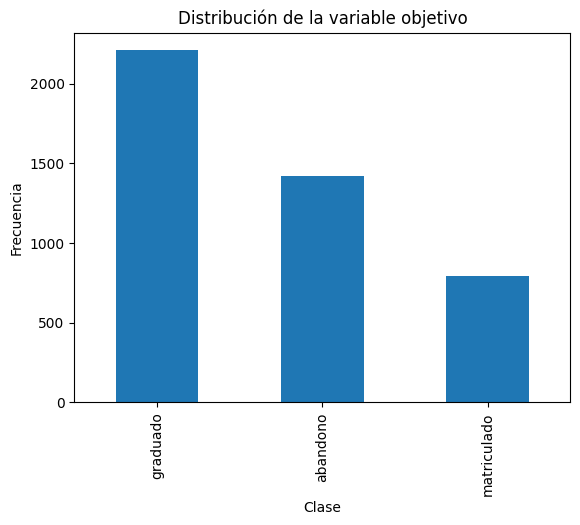

In [20]:
import matplotlib.pyplot as plt

df["objetivo"].value_counts().plot(kind="bar")
plt.title("Distribución de la variable objetivo")
plt.xlabel("Clase")
plt.ylabel("Frecuencia")
plt.show()

Confirmo mi razonamiento anterior. La clase más frecuente es la de graduado seguida por el abandono. Cierra la lista la clase de matriculados.

**5.9. Resumen del target de regresión**

Quiero estudiar el target de regresión, que representa la nota media del segundo semestre. Al no ser una clase sino una métrica tengo que utilizar métodos diferentes a los usados con el target de clasificación.

In [21]:
df["nota_media_2sem"].describe()

count    4424.000000
mean       10.230206
std         5.210808
min         0.000000
25%        10.750000
50%        12.200000
75%        13.333333
max        18.571429
Name: nota_media_2sem, dtype: float64

Obtengo diferentes métricas que describen mi target de regresión. Es importante mencionar que la nota es sobre 20, es decir, toma valores del 0 al 20.


La nota media del segundo semestre está en torno al 10'2. El valor máximo es de 18'57 y el mínimo de 0. Dado que el 75% de los datos están por debajo del 13'3 y el 50% por debajo del 12'2, interpreto que hay menos notas altas que bajas. Esto tiene sentido, no solo lógico, sino también métrico dado el valor de la desviación típica.

**5.10. Histograma del target de regresión**

Para comprobar que mi razonamiento anterior es correcto me apoyo en un histograma. De nuevo, utilizo la librería matplotlib.

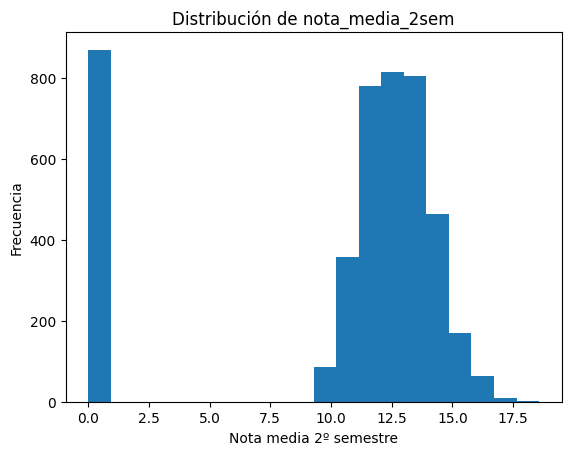

In [22]:
df["nota_media_2sem"].plot(kind="hist", bins=20)
plt.title("Distribución de nota_media_2sem")
plt.xlabel("Nota media 2º semestre")
plt.ylabel("Frecuencia")
plt.show()

Con el gráfico obtengo una información mucho más interpretable que en las métricas anteriores. Si bien mi razonamiento no es incorrecto, estaba dejando escapar varios detalles. 

En primer lugar, me llama la atención el alto número de notas alrededor del 0, superando los 800, lo que representa casi un 20% del dataset. Sería interesante estudiar si estos valores corresponden a notas que no han sido evaluadas o de abandonos.

Por otra parte, he de destacar que, dado la gran cantidad de datos que tienen una nota mínima, no consideraría la media una métrica muy informativa. De hecho, gráficamente se observa que debería ser algo mayor, pero el peso de los valores cercanos al 0 la disminuyen. En este caso, la mejor métrica sería la mediana. 

In [23]:
df["nota_media_2sem"].median()

np.float64(12.2)

Esta métrica ya encaja mucho más con lo que intuía.

**5.11. Estadística descriptiva de todas las variables numéricas**

Utilizo la función describe de pandas para estudiar las métricas de cada una de las variables numéricas del dataset.

In [24]:
df.describe()

,orden_solicitud,nota_cualificacion_previa,nota_admision,edad_al_matricularse,asignaturas_1sem_convalidadas,asignaturas_1sem_matriculadas,asignaturas_1sem_evaluadas,asignaturas_1sem_aprobadas,nota_media_1sem,asignaturas_1sem_sin_evaluacion,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.727848,132.613314,126.978119,23.265145,0.709991,6.270570,8.299051,4.706600,10.640822,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,1.313793,13.188332,14.482001,7.587816,2.360507,2.480178,4.179106,3.094238,4.843663,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,0.000000,95.000000,95.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,125.000000,117.900000,19.000000,0.000000,5.000000,6.000000,3.000000,11.000000,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,133.100000,126.100000,20.000000,0.000000,6.000000,8.000000,5.000000,12.285714,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,2.000000,140.000000,134.800000,25.000000,0.000000,7.000000,10.000000,6.000000,13.400000,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,9.000000,190.000000,190.000000,70.000000,20.000000,26.000000,45.000000,26.000000,18.875000,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


Obtengo una tabla con las siguientes métricas para cada variable numérica. Tenemos el conteo, la media, la desviación típica, el mínimo, los percentiles 25, 50 y 75 y finalmente el máximo. Esto nos ayuda a conocer mejor las variables.

**5.12. Frecuencias de variables categóricas**

Estudio la frecuencia de algunas variables categóricas para conocer cuántos casos hay en cada categoría.

In [25]:
df["genero"].value_counts()

genero
mujer     2868
hombre    1556
Name: count, dtype: int64

In [26]:
df["nacionalidad"].value_counts()

nacionalidad
portuguesa      4314
brasilena         38
santotomense      14
espanola          13
caboverdiana      13
guineana           5
moldava            3
italiana           3
ucraniana          3
rumana             2
angolana           2
mexicana           2
mozambiquena       2
alemana            2
rusa               2
turca              1
neerlandesa        1
colombiana         1
cubana             1
inglesa            1
lituana            1
Name: count, dtype: int64

In [27]:
df["becado"].value_counts()

becado
no    3325
si    1099
Name: count, dtype: int64

Tras este apartado del estudio observo lo siguiente de mis observaciones. Tengo más mujeres (casi el doble) que hombres entre mis observaciones.En adición, la nacionalidad de las observaciones es mayoritariamente portuguesa. Finalmente, tengo alrededor de 1/4 de observaciones de becados. El resto no son becados.

**5.13. Correlación entre variables numéricas**

Estudio la correlación entre las variables numéricas del dataset para identificar relaciones lineales fuertes entre predictores, 
y también entre predictores y el target de regresión (nota_media_2sem). Esto es útil para conocer qué variables pueden aportar más 
en la tarea de regresión y para detectar posibles problemas de multicolinealidad.

In [28]:
import matplotlib.pyplot as plt

numericas_df = df.select_dtypes(include="number")
corr = numericas_df.corr()

#mostrar las correlaciones más altas con el target de regresión
print("Correlación con nota_media_2sem (top 10):")
print(corr["nota_media_2sem"].drop("nota_media_2sem").abs().sort_values(ascending=False).head(10).round(3))

Correlación con nota_media_2sem (top 10):
nota_media_1sem                  0.837
asignaturas_2sem_aprobadas       0.761
asignaturas_1sem_aprobadas       0.686
asignaturas_2sem_evaluadas       0.453
asignaturas_2sem_matriculadas    0.395
asignaturas_1sem_matriculadas    0.362
asignaturas_1sem_evaluadas       0.355
edad_al_matricularse             0.173
asignaturas_1sem_convalidadas    0.133
asignaturas_2sem_convalidadas    0.130
Name: nota_media_2sem, dtype: float64


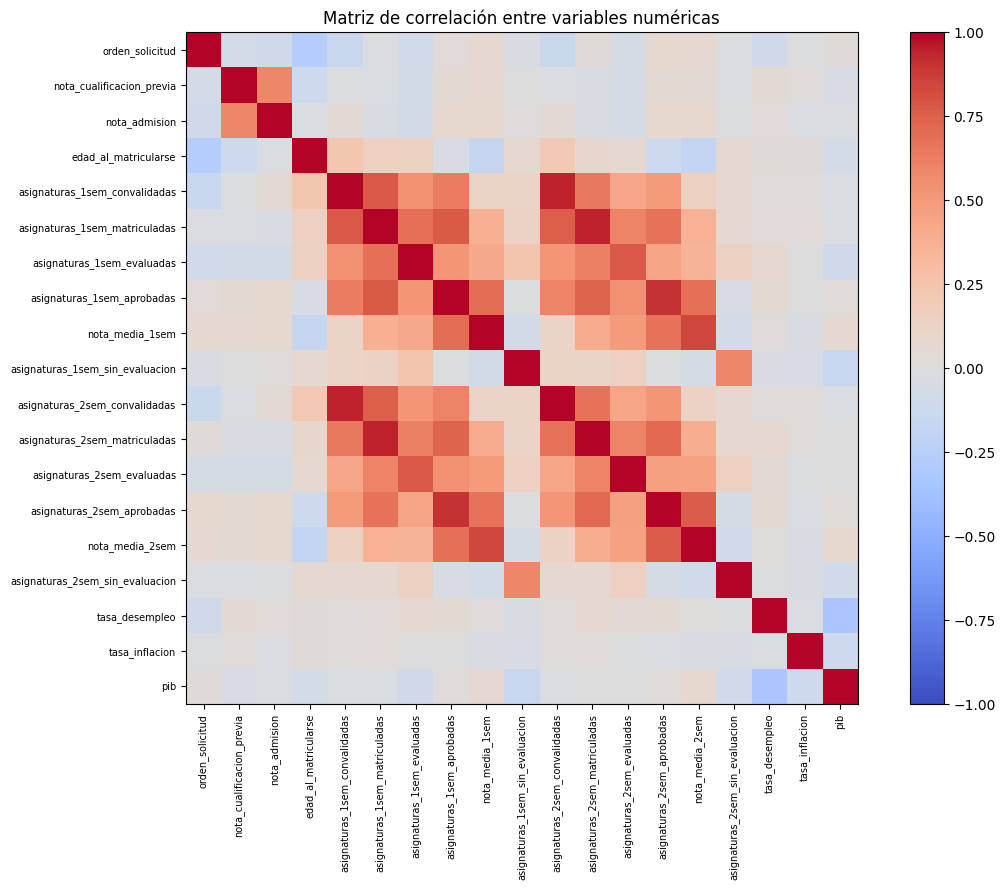

In [29]:
#mapa de calor de la matriz de correlación
fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90, fontsize=7)
ax.set_yticklabels(corr.columns, fontsize=7)
plt.colorbar(im)
plt.title("Matriz de correlación entre variables numéricas")
plt.tight_layout()
plt.show()

La matriz muestra qué variables numéricas están más relacionadas entre sí y con el target de regresión. Las variables del primer semestre tienen correlación alta con las del segundo, lo que confirma que serán predictores útiles.

También se observa que las variables del segundo semestre (asignaturas aprobadas, evaluadas, matriculadas) tienen correlaciones altas con el target de regresión. Esto era esperable porque pertenecen al mismo periodo, y es precisamente el motivo por el que se excluyen como predictores en la tarea de regresión para evitar leakage.

**5.14. Relación entre las variables de rendimiento y la clase objetivo**

Estudio cómo se distribuyen las notas medias del primer y segundo semestre según la clase objetivo (abandono, matriculado, graduado). 
Esto me ayuda a entender si el rendimiento académico tiene una relación visible con la trayectoria final del estudiante.

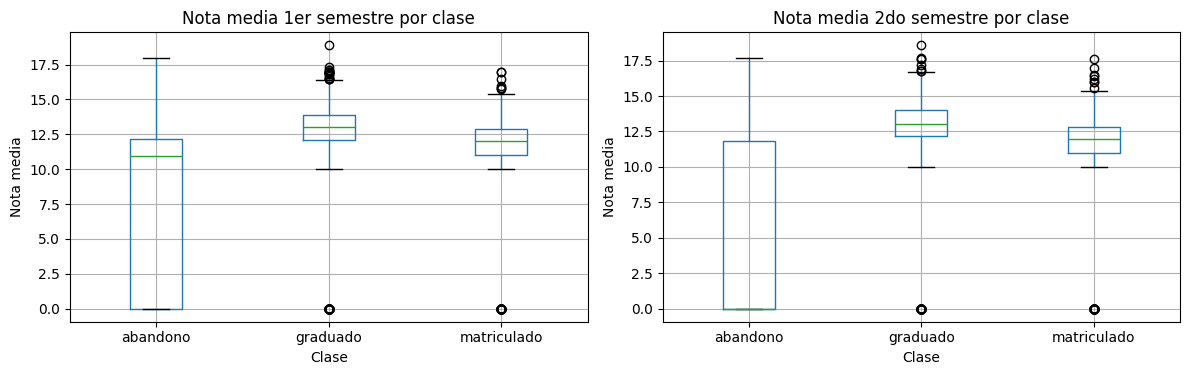

In [30]:
#boxplots de nota media por clase objetivo
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df.boxplot(column="nota_media_1sem", by="objetivo", ax=axes[0])
axes[0].set_title("Nota media 1er semestre por clase")
axes[0].set_xlabel("Clase")
axes[0].set_ylabel("Nota media")

df.boxplot(column="nota_media_2sem", by="objetivo", ax=axes[1])
axes[1].set_title("Nota media 2do semestre por clase")
axes[1].set_xlabel("Clase")
axes[1].set_ylabel("Nota media")

plt.suptitle("")
plt.tight_layout()
plt.show()

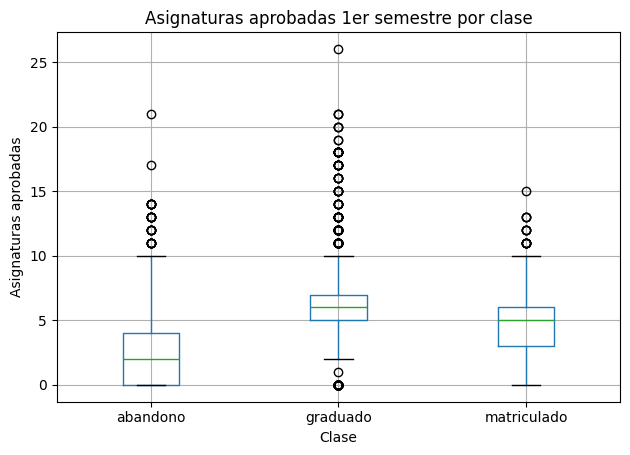

In [31]:
#boxplot de asignaturas aprobadas 1er semestre por clase
df.boxplot(column="asignaturas_1sem_aprobadas", by="objetivo")
plt.title("Asignaturas aprobadas 1er semestre por clase")
plt.xlabel("Clase")
plt.ylabel("Asignaturas aprobadas")
plt.suptitle("")
plt.tight_layout()
plt.show()

Los boxplots muestran diferencias claras entre las tres clases. Los estudiantes que abandonan tienen notas y asignaturas aprobadas mucho más bajas. Las variables de rendimiento del primer semestre van a ser predictores fuertes en clasificación y regresión.

**5.15. Conclusión del estudio del dataset**

El dataset tiene 4424 observaciones y 37 variables, sin valores nulos ni filas duplicadas.

La variable objetivo de clasificación tiene un leve desbalanceo: graduado (49.9%), abandono (32.1%) y matriculado (17.9%). Este detalle habrá que tenerlo en cuenta al elegir métricas de evaluación.

La variable de regresión (nota_media_2sem) va de 0 a 20 y tiene una acumulación interesante de valores cercanos a 0 (en torno a 800 observaciones). Probablemente corresponden a estudiantes que abandonaron sin completar evaluaciones, pero esto se ha de estudiar. La mediana (12.2) describe mejor el rendimiento típico que la media (10.2) debido a la asimetría de los datos.

La correlación entre nota_media_1sem y nota_media_2sem es de 0.837, lo cual anticipa que el primer semestre será un predictor fuerte en regresión. Los boxplots me dejan ver que las tres clases se diferencian claramente en rendimiento: los estudiantes que abandonan tienen notas y asignaturas aprobadas mucho más bajas. De nuevo, este detalle también tendré que tenerlo en cuenta durante el desarrollo de mi proyecto.

Tras este análisis tanto del dataset como de las variables puedo pasar a la construcción de mi modelo de machine learning.